In [1]:
%load_ext autoreload
%autoreload 2

import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from src.config import PROJECT_ROOT, DATA_DIR, RUNS_DIR, SEED, CIFAR100_MEAN, CIFAR100_STD

from torchvision.datasets import CIFAR100
from torchvision import transforms
import torch

In [ ]:
# ── 第一遍：transform=None，看磁盘原始格式 ──
train_raw = CIFAR100(root=DATA_DIR, train=True, download=True, transform=None)
test_raw  = CIFAR100(root=DATA_DIR, train=False, download=True, transform=None)

img, label = train_raw[0]
print("type(img):   ", type(img))
print("img.size:    ", img.size)      # PIL 用的是 .size，且是 (宽, 高)
print("img.mode:    ", img.mode)
print("type(label): ", type(label), "| label:", label)

In [6]:
# ── 第二遍：加 ToTensor，对比格式变化 ──
# download=False：证明第一次下过就不用再下了
train_t = CIFAR100(root=DATA_DIR, train=True, download=False,
                    transform=transforms.ToTensor())
test_t = CIFAR100(root=DATA_DIR, train=False, download=False,
                    transform=transforms.ToTensor())

img_t, label_t = train_t[0]           # 同一张图（顺序一致），对比才公平
print("type:    ", type(img_t))
print("shape:   ", img_t.shape)       # [3, 32, 32] → CHW
print("dtype:   ", img_t.dtype)       # float32
print("值域:    ", float(img_t.min()), "~", float(img_t.max()))   # 约 [0, 1]

type:     <class 'torch.Tensor'>
shape:    torch.Size([3, 32, 32])
dtype:    torch.float32
值域:     0.003921568859368563 ~ 1.0


In [8]:
tmp = CIFAR100(root=DATA_DIR, train=True, download=False,transform=transforms.ToTensor())
imgs = torch.stack([tmp[i][0] for i in range(len(tmp))])
mean = imgs.mean(dim=(0, 2, 3))
std = imgs.std(dim=(0, 2, 3), unbiased=False)

print("mean:", tuple(round(float(v), 4) for v in mean))
print("std: ", tuple(round(float(v), 4) for v in std))


mean: (0.5071, 0.4866, 0.4409)
std:  (0.2673, 0.2564, 0.2762)


In [2]:
train_tf = transforms.Compose([
    transforms.ToTensor(),                                 # PIL → tensor, CHW, [0,1]
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),     # 逐通道 (x-mean)/std
])

test_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
])

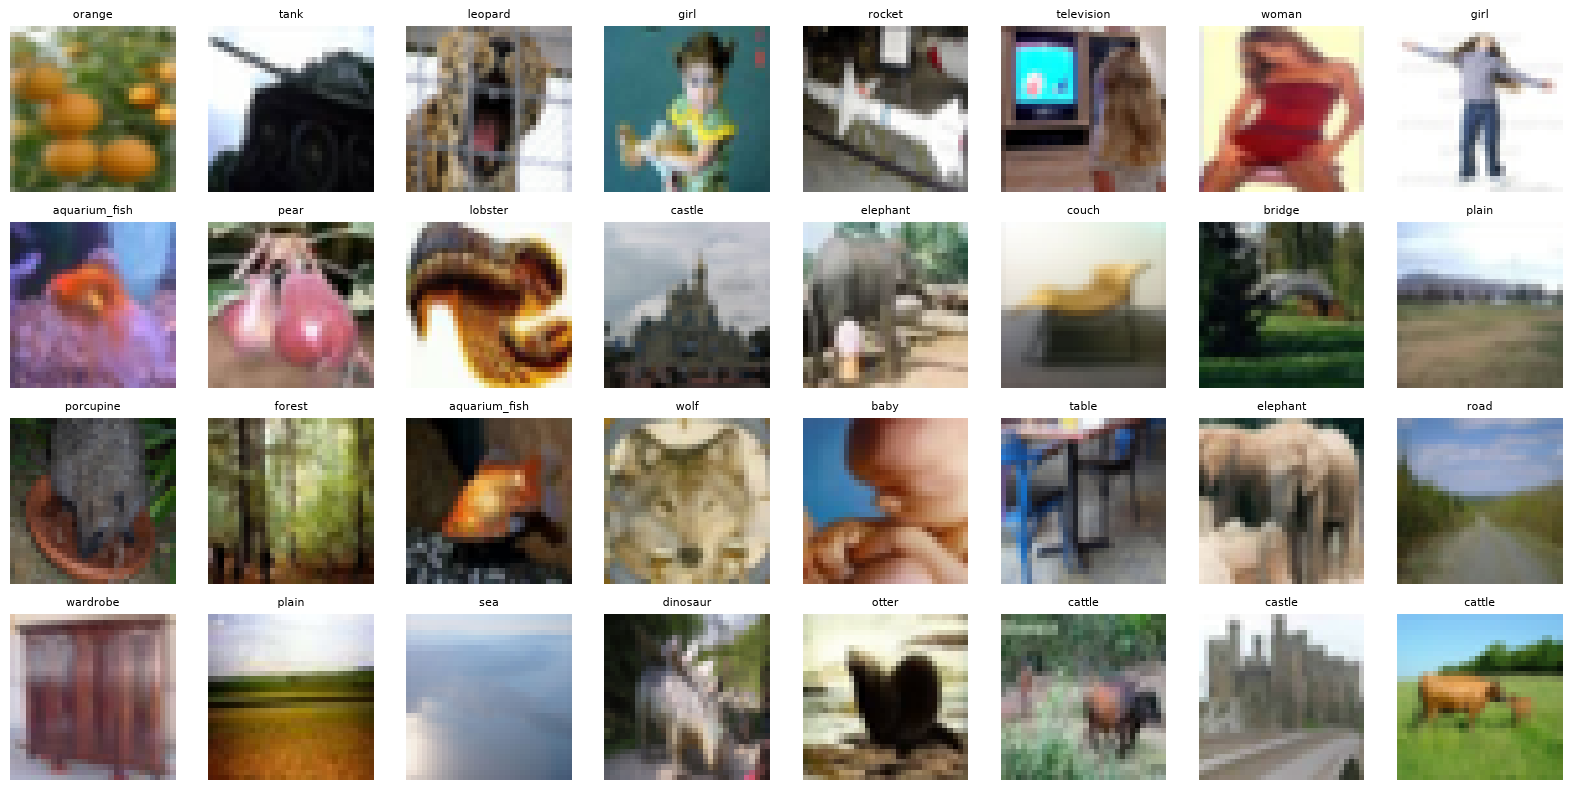

In [3]:
import matplotlib.pyplot as plt, torch
from src.data import build_datasets, build_loaders

train_ds, test_ds = build_datasets()
train_loader, test_loader = build_loaders(batch_size=128)

def denormalize(t):      # (3,32,32) → 可 imshow 的 (32,32,3)
    mean = torch.tensor(CIFAR100_MEAN).view(3, 1, 1)
    std  = torch.tensor(CIFAR100_STD).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

imgs, labels = next(iter(train_loader))
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for ax, img, lb in zip(axes.ravel(), imgs[:32], labels[:32]):
    ax.imshow(denormalize(img))
    ax.set_title(train_ds.classes[lb.item()], fontsize=8)
    ax.axis("off")
plt.tight_layout()